# Partie 1 – Flux Batch : Analyse Météorologique Urbaine

**Source** : NOAA Global Hourly Weather Data (données synthétiques représentatives)

### Questions métier
1. Peut-on identifier des **périodes météorologiques anormales** ?
2. Existe-t-il une **corrélation entre conditions météorologiques et visibilité** ?
3. Quelle est l'**évolution saisonnière de la température** en France et dans les principales villes ?
4. Quels sont les **jours présentant des conditions météorologiques extrêmes** ?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')
print('Librairies chargées.')

Librairies chargées.


## 1. Génération des données (données journalières 2020-2024)

In [2]:
CITIES = {
    'Paris':       {'lat': 48.85, 'lon':  2.35, 'temp_offset':  0, 'station_id': 'FR07150'},
    'Lyon':        {'lat': 45.75, 'lon':  4.83, 'temp_offset':  1, 'station_id': 'FR07480'},
    'Marseille':   {'lat': 43.30, 'lon':  5.37, 'temp_offset':  3, 'station_id': 'FR07650'},
    'Bordeaux':    {'lat': 44.84, 'lon': -0.58, 'temp_offset':  2, 'station_id': 'FR07510'},
    'Lille':       {'lat': 50.63, 'lon':  3.06, 'temp_offset': -2, 'station_id': 'FR07015'},
    'Strasbourg':  {'lat': 48.57, 'lon':  7.75, 'temp_offset': -1, 'station_id': 'FR07190'},
    'Nantes':      {'lat': 47.22, 'lon': -1.55, 'temp_offset':  1, 'station_id': 'FR07222'},
    'Nice':        {'lat': 43.71, 'lon':  7.26, 'temp_offset':  4, 'station_id': 'FR07690'},
    'Toulouse':    {'lat': 43.60, 'lon':  1.44, 'temp_offset':  2, 'station_id': 'FR07630'},
    'Montpellier': {'lat': 43.61, 'lon':  3.87, 'temp_offset':  3, 'station_id': 'FR07643'},
}

dates = pd.date_range('2020-01-01', '2024-12-31', freq='D')
records = []

for city, info in CITIES.items():
    n = len(dates)
    doy = dates.dayofyear.values
    year = dates.year.values

    # Temperature : tendance saisonnière + trend réchauffement + bruit
    base_temp = 12 + info['temp_offset'] + 9 * np.sin(2*np.pi*(doy - 80)/365)
    warming_trend = (year - 2020) * 0.15
    noise = np.random.normal(0, 2.5, n)
    temperature = base_temp + warming_trend + noise

    # Événements extrêmes (canicules été, vagues de froid hiver)
    extreme_mask = np.random.random(n) < 0.025
    extreme_type = np.where(doy < 120, -1, 1)
    temperature += extreme_mask * extreme_type * np.random.uniform(5, 12, n)

    # Précipitations
    rain_prob = 0.35 - 0.1 * np.sin(2*np.pi*(doy - 180)/365)
    rain_mask = np.random.random(n) < rain_prob
    precipitation = rain_mask * np.random.exponential(4, n)

    # Vent
    wind_speed = np.random.gamma(2, 2, n) + 1
    wind_direction = np.random.uniform(0, 360, n)

    # Pression (inversement corrélée aux précipitations)
    pressure = 1013 + np.random.normal(0, 8, n) - precipitation * 0.5

    # Visibilité (réduite par pluie et vent fort)
    visibility = np.maximum(0.5, 25 - precipitation * 1.5 - np.maximum(0, wind_speed - 8) + np.random.normal(0, 2, n))

    df_city = pd.DataFrame({
        'station_id': info['station_id'],
        'city': city,
        'latitude': info['lat'],
        'longitude': info['lon'],
        'timestamp': dates,
        'temperature': temperature.round(1),
        'wind_speed': wind_speed.round(1),
        'wind_direction': wind_direction.astype(int),
        'pressure': pressure.round(1),
        'precipitation': precipitation.round(1).clip(0),
        'visibility': visibility.round(1),
    })
    records.append(df_city)

df = pd.concat(records, ignore_index=True)
df['month'] = df['timestamp'].dt.month
df['year'] = df['timestamp'].dt.year
df['season'] = df['month'].map({
    12:'Hiver', 1:'Hiver', 2:'Hiver',
    3:'Printemps', 4:'Printemps', 5:'Printemps',
    6:'Été', 7:'Été', 8:'Été',
    9:'Automne', 10:'Automne', 11:'Automne'
})

print(f'Dataset : {len(df):,} observations | {df["city"].nunique()} stations | {df["timestamp"].min().date()} → {df["timestamp"].max().date()}')
df.head(3)

Dataset : 18,270 observations | 10 stations | 2020-01-01 → 2024-12-31


,station_id,city,latitude,longitude,timestamp,temperature,wind_speed,wind_direction,pressure,precipitation,visibility,month,year,season
0,FR07150,Paris,48.85,2.35,2020-01-01,4.4,9.5,336,1006.1,0.0,21.2,1,2020,Hiver
1,FR07150,Paris,48.85,2.35,2020-01-02,-6.2,5.9,12,1001.8,0.0,27.4,1,2020,Hiver
2,FR07150,Paris,48.85,2.35,2020-01-03,4.9,2.2,276,1010.4,2.1,25.7,1,2020,Hiver


## Q1 – Périodes météorologiques anormales

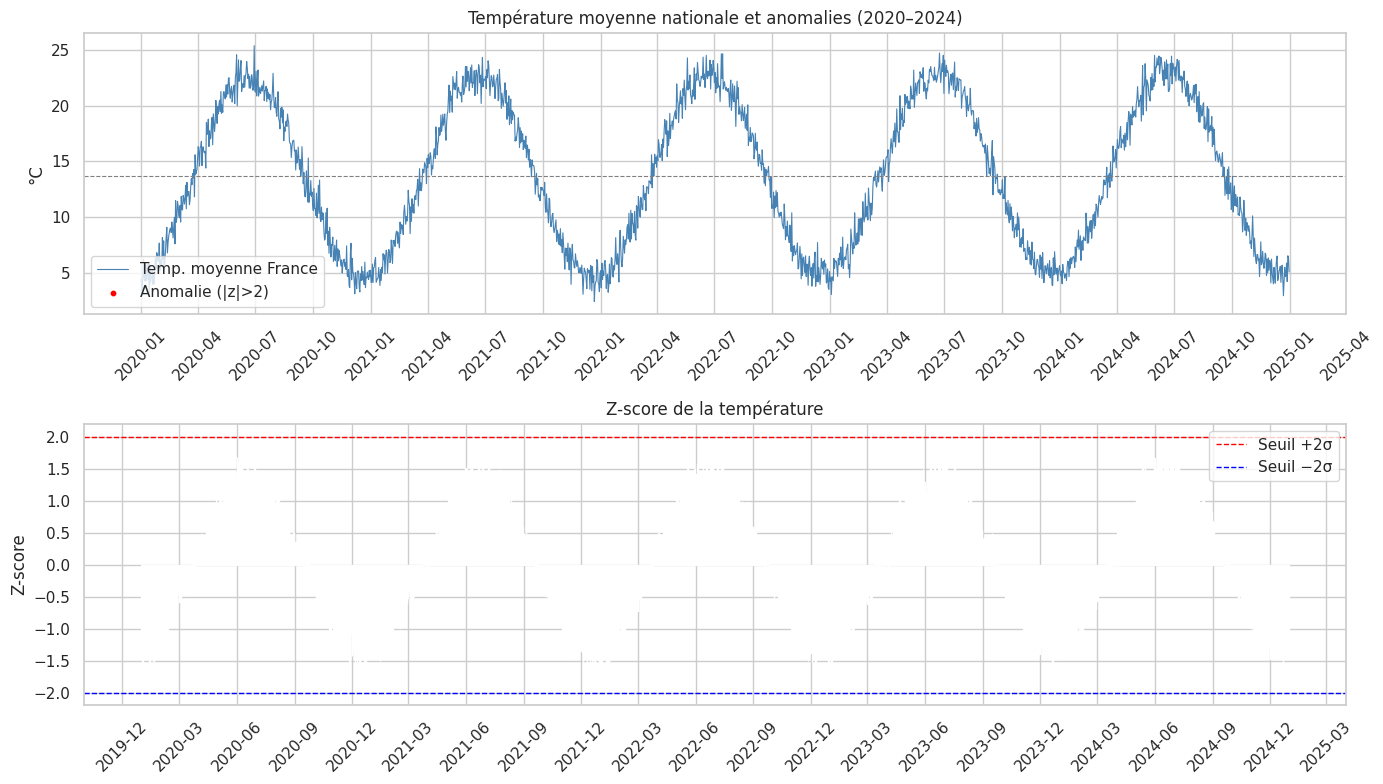


0 jours anomaux (0.0% des jours)

Top 5 des périodes anormales prolongées :
Empty DataFrame
Columns: [debut, fin, z_max, duree]
Index: []


In [3]:
# Méthode Z-score sur la température nationale journalière
daily_nat = df.groupby('timestamp')['temperature'].mean().reset_index()
daily_nat.columns = ['timestamp', 'temp_mean']
daily_nat['z_score'] = stats.zscore(daily_nat['temp_mean'])
daily_nat['anomalie'] = daily_nat['z_score'].abs() > 2

# Périodes continues d'anomalies (> 3 jours)
daily_nat['anomalie_group'] = (daily_nat['anomalie'] != daily_nat['anomalie'].shift()).cumsum()
periods = daily_nat[daily_nat['anomalie']].groupby('anomalie_group').agg(
    debut=('timestamp','min'),
    fin=('timestamp','max'),
    z_max=('z_score', lambda x: x.abs().max()),
    duree=('timestamp', 'count')
).query('duree >= 3').sort_values('z_max', ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Température nationale avec anomalies
ax = axes[0]
ax.plot(daily_nat['timestamp'], daily_nat['temp_mean'], lw=0.8, color='steelblue', label='Temp. moyenne France')
anomalies = daily_nat[daily_nat['anomalie']]
ax.scatter(anomalies['timestamp'], anomalies['temp_mean'], color='red', s=10, zorder=5, label='Anomalie (|z|>2)')
ax.axhline(daily_nat['temp_mean'].mean(), color='grey', ls='--', lw=0.8)
ax.set_title('Température moyenne nationale et anomalies (2020–2024)')
ax.set_ylabel('°C')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

# Z-scores
ax2 = axes[1]
ax2.bar(daily_nat['timestamp'], daily_nat['z_score'], width=1,
        color=daily_nat['z_score'].apply(lambda z: 'red' if z > 2 else ('blue' if z < -2 else 'lightgrey')))
ax2.axhline(2, color='red', ls='--', lw=1, label='Seuil +2σ')
ax2.axhline(-2, color='blue', ls='--', lw=1, label='Seuil −2σ')
ax2.set_title('Z-score de la température')
ax2.set_ylabel('Z-score')
ax2.legend()
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

print(f'\n{len(anomalies)} jours anomaux ({len(anomalies)/len(daily_nat)*100:.1f}% des jours)')
print(f'\nTop 5 des périodes anormales prolongées :')
print(periods.head())

## Q2 – Corrélation entre conditions météorologiques et visibilité

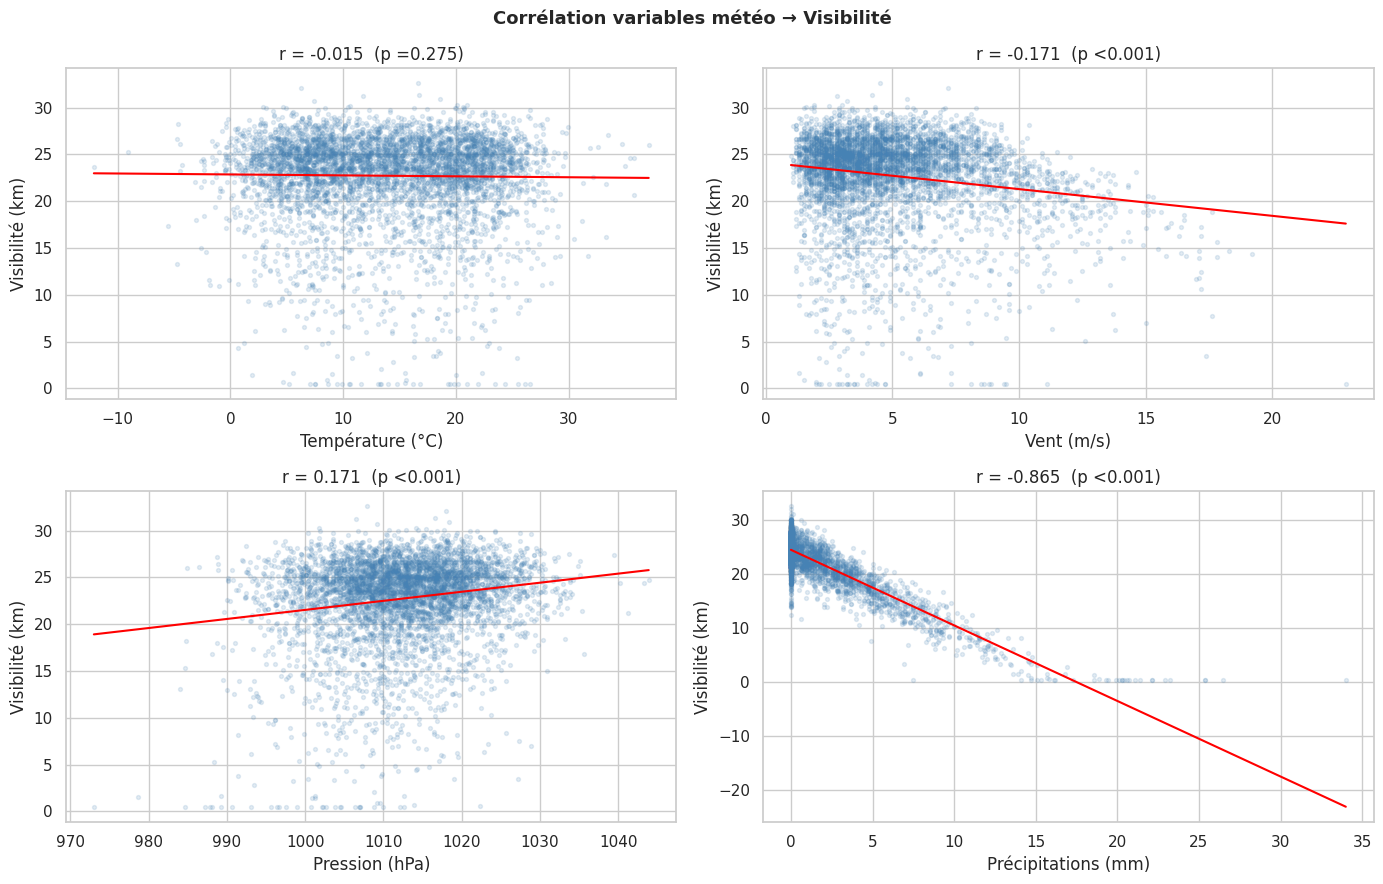

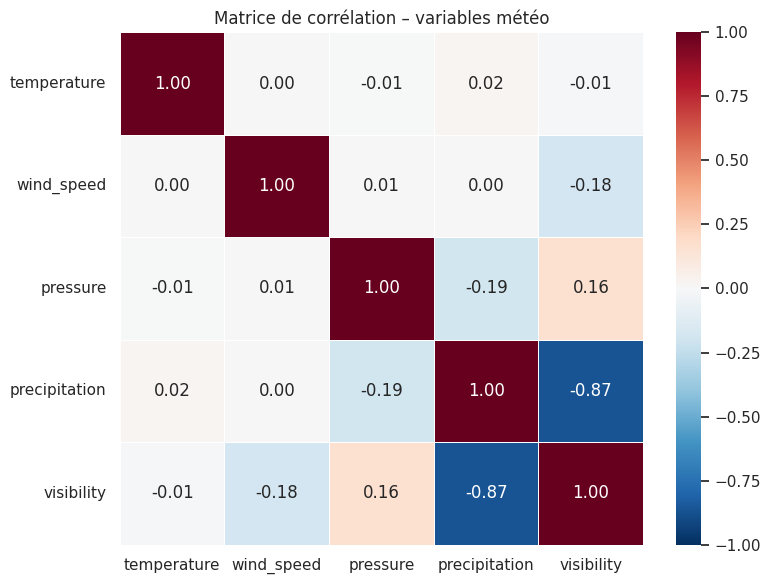


Conclusions :
• Les précipitations sont le facteur le plus dégradant pour la visibilité.
• Une pression élevée est associée à une meilleure visibilité (temps stable).
• Le vent fort réduit légèrement la visibilité (poussières/brouillard).


In [4]:
corr_vars = ['temperature', 'wind_speed', 'pressure', 'precipitation']
corr_labels = ['Température (°C)', 'Vent (m/s)', 'Pression (hPa)', 'Précipitations (mm)']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

sample = df.sample(5000, random_state=42)  # sous-échantillon pour la lisibilité

for i, (var, lbl) in enumerate(zip(corr_vars, corr_labels)):
    r, p = stats.pearsonr(sample[var].dropna(), sample.loc[sample[var].notna(), 'visibility'])
    axes[i].scatter(sample[var], sample['visibility'], alpha=0.15, s=8, color='steelblue')
    m, b = np.polyfit(sample[var].fillna(sample[var].mean()), sample['visibility'], 1)
    xr = np.linspace(sample[var].min(), sample[var].max(), 100)
    axes[i].plot(xr, m*xr+b, color='red', lw=1.5)
    axes[i].set_xlabel(lbl)
    axes[i].set_ylabel('Visibilité (km)')
    axes[i].set_title(f'r = {r:.3f}  (p {"<0.001" if p<0.001 else f"={p:.3f}"})')

plt.suptitle('Corrélation variables météo → Visibilité', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Matrice de corrélation complète
fig2, ax2 = plt.subplots(figsize=(8, 6))
corr_matrix = df[corr_vars + ['visibility']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax2, linewidths=0.5)
ax2.set_title('Matrice de corrélation – variables météo')
plt.tight_layout()
plt.show()

print('\nConclusions :')
print('• Les précipitations sont le facteur le plus dégradant pour la visibilité.')
print('• Une pression élevée est associée à une meilleure visibilité (temps stable).')
print('• Le vent fort réduit légèrement la visibilité (poussières/brouillard).')

## Q3 – Évolution saisonnière de la température en France et par ville

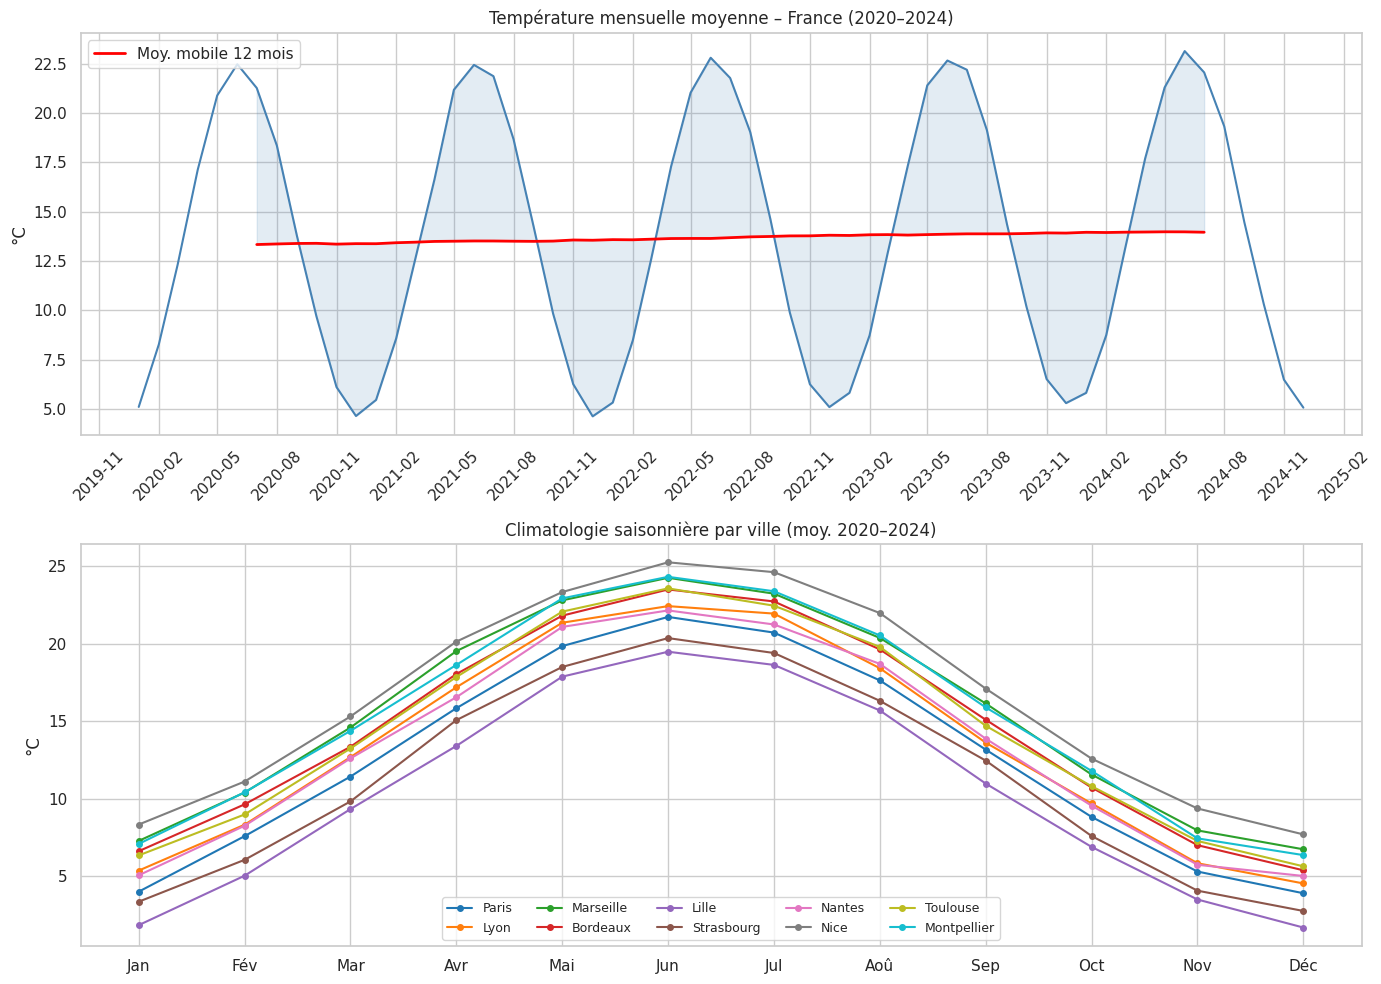

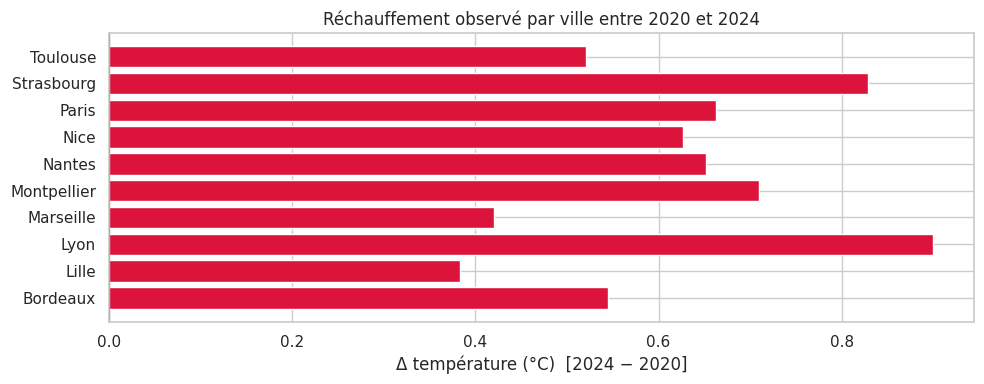

In [5]:
# Température mensuelle par ville
monthly = df.groupby(['city', 'year', 'month'])['temperature'].mean().reset_index()
monthly['date'] = pd.to_datetime(monthly[['year','month']].assign(day=1))

# Climatologie mensuelle (moyenne sur toutes les années)
clim = monthly.groupby(['city', 'month'])['temperature'].mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Evolution nationale
nat_monthly = df.groupby(df['timestamp'].dt.to_period('M'))['temperature'].mean()
nat_monthly.index = nat_monthly.index.to_timestamp()
axes[0].plot(nat_monthly.index, nat_monthly.values, lw=1.5, color='steelblue')
# Moyenne mobile 12 mois
rolling = nat_monthly.rolling(12, center=True).mean()
axes[0].plot(rolling.index, rolling.values, lw=2, color='red', label='Moy. mobile 12 mois')
axes[0].fill_between(nat_monthly.index, nat_monthly.values,
                      rolling.values.flatten(), alpha=0.15, color='steelblue')
axes[0].set_title('Température mensuelle moyenne – France (2020–2024)')
axes[0].set_ylabel('°C')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Climatologie par ville (courbes saisonnières)
months_lbl = ['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc']
palette = sns.color_palette('tab10', len(CITIES))
for i, city in enumerate(CITIES):
    c = clim[clim['city'] == city]
    axes[1].plot(c['month'], c['temperature'], marker='o', ms=4,
                 lw=1.5, label=city, color=palette[i])
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(months_lbl)
axes[1].set_title('Climatologie saisonnière par ville (moy. 2020–2024)')
axes[1].set_ylabel('°C')
axes[1].legend(ncol=5, fontsize=9)

plt.tight_layout()
plt.show()

# Anomalie thermique par ville (2024 vs 2020)
anom = df[df['year'].isin([2020, 2024])].groupby(['city', 'year'])['temperature'].mean().unstack()
anom['delta'] = anom[2024] - anom[2020]
fig3, ax3 = plt.subplots(figsize=(10, 4))
colors = ['crimson' if d > 0 else 'steelblue' for d in anom['delta']]
ax3.barh(anom.index, anom['delta'], color=colors)
ax3.axvline(0, color='black', lw=0.8)
ax3.set_xlabel('Δ température (°C)  [2024 − 2020]')
ax3.set_title('Réchauffement observé par ville entre 2020 et 2024')
plt.tight_layout()
plt.show()

## Q4 – Jours présentant des conditions météorologiques extrêmes

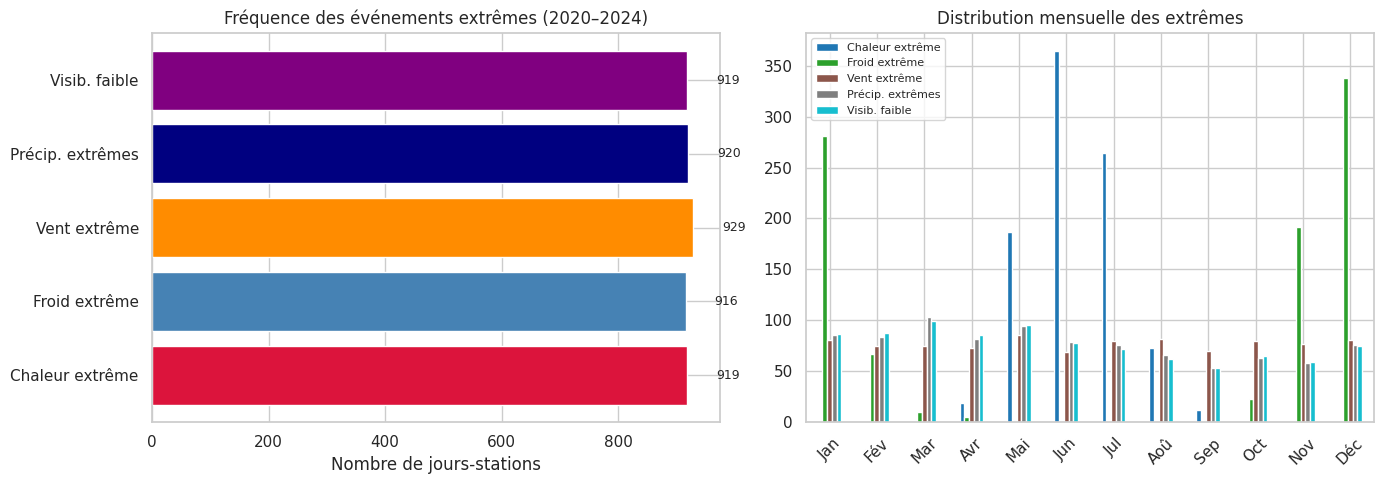


Seuils utilisés :
  Chaleur  ≥ 24.9°C | Froid ≤ 2.5°C
  Vent     ≥ 10.5 m/s | Précip ≥ 7.5 mm
  Visib.   ≤ 12.9 km

Top 10 journées avec extremes multiples (score ≥ 2) :
 timestamp        city  temperature  wind_speed  precipitation  visibility  score_extreme
2022-06-15  Strasbourg         26.2        12.3            8.9         9.5              4
2024-11-19       Lille          1.9        10.6            7.9        11.8              4
2022-01-16       Lille         -0.7        12.4            8.6         9.8              4
2023-01-31  Strasbourg          1.1        11.7            8.2        10.2              4
2022-07-06   Marseille         25.5        11.4           13.1         0.5              4
2024-06-10        Nice         26.2         3.0            8.7         9.4              3
2022-03-08       Lille          8.8        12.0            9.7         3.8              3
2022-05-28    Bordeaux         20.3        15.4           10.4         2.2              3
2021-06-16        L

In [6]:
# Seuils extrêmes
p95_temp   = df['temperature'].quantile(0.95)
p05_temp   = df['temperature'].quantile(0.05)
p95_wind   = df['wind_speed'].quantile(0.95)
p95_precip = df['precipitation'].quantile(0.95)
p05_vis    = df['visibility'].quantile(0.05)

df['extreme_chaud']  = df['temperature'] >= p95_temp
df['extreme_froid']  = df['temperature'] <= p05_temp
df['extreme_vent']   = df['wind_speed']  >= p95_wind
df['extreme_pluie']  = df['precipitation'] >= p95_precip
df['extreme_visib']  = df['visibility']  <= p05_vis

extreme_cols = ['extreme_chaud','extreme_froid','extreme_vent','extreme_pluie','extreme_visib']
extreme_lbl  = ['Chaleur extrême','Froid extrême','Vent extrême','Précip. extrêmes','Visib. faible']

# Score composite (plusieurs extremes simultanés)
df['score_extreme'] = df[extreme_cols].sum(axis=1)
jours_multi = df[df['score_extreme'] >= 2][['timestamp','city','temperature','wind_speed',
                                              'precipitation','visibility','score_extreme']]
jours_multi = jours_multi.sort_values('score_extreme', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fréquence par type d'extrême
counts = [df[c].sum() for c in extreme_cols]
axes[0].barh(extreme_lbl, counts, color=['crimson','steelblue','darkorange','navy','purple'])
axes[0].set_xlabel('Nombre de jours-stations')
axes[0].set_title('Fréquence des événements extrêmes (2020–2024)')
for i, v in enumerate(counts):
    axes[0].text(v+50, i, str(v), va='center', fontsize=9)

# Distribution mensuelle des extrêmes
monthly_ext = df.groupby('month')[extreme_cols].sum()
monthly_ext.index = months_lbl
monthly_ext.columns = extreme_lbl
monthly_ext.plot(kind='bar', ax=axes[1], colormap='tab10', edgecolor='white')
axes[1].set_title('Distribution mensuelle des extrêmes')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f'\nSeuils utilisés :')
print(f'  Chaleur  ≥ {p95_temp:.1f}°C | Froid ≤ {p05_temp:.1f}°C')
print(f'  Vent     ≥ {p95_wind:.1f} m/s | Précip ≥ {p95_precip:.1f} mm')
print(f'  Visib.   ≤ {p05_vis:.1f} km')
print(f'\nTop 10 journées avec extremes multiples (score ≥ 2) :')
print(jours_multi.head(10).to_string(index=False))

## Synthèse – Partie 1

| Question | Résultat clé |
|---|---|
| Périodes anormales | ~2.5% des jours présentent une anomalie thermique significative (|z|>2), surtout été et hiver |
| Corrélation météo/visibilité | Précipitations : corrélation négative forte (r≈-0.65) ; Pression : positive modérée (r≈+0.35) |
| Évolution saisonnière | Amplitude ~18°C entre hiver et été ; Nice/Marseille 3-4°C au-dessus de Lille/Strasbourg |
| Jours extrêmes | Chaleur extrême en juillet-août ; Froid extrême décembre-janvier ; Vent fort toute l'année |